In [47]:
import finesse
from finesse.components import Space, Lens, Laser, Nothing
from finesse.knm import Map
from finesse.utilities.maps import circular_aperture
from finesse.tracing.tools import propagate_beam

import numpy as np
import matplotlib.pyplot as plt

import ipywidgets as widgets
from ipywidgets import FloatSlider
from IPython.display import display
import time


In [48]:
INCH = 0.0254

def make_circular_aperture_map(diameter_inch, grid_pad=1.25, N=512, opd=None):
    """
    Hard circular aperture mask (amplitude) + optional OPD aberration map (meters).
    Attach to a Lens via lens.OPD_map.
    """
    R_ap = 0.5 * diameter_inch * INCH
    half_width = grid_pad * R_ap

    x = np.linspace(-half_width, half_width, N)
    y = np.linspace(-half_width, half_width, N)

    amp = circular_aperture(x, y, R_ap)
    if opd is None:
        opd = np.zeros((len(y), len(x)))

    return Map(x, y, amplitude=amp, opd=opd)


def setup_model(f1, f2, f3, f4, d1, d2, d3, d4, d5, visualise=False):
    M = finesse.model.Model()
    M.lambda0 = 1550e-9

    laser_1550 = Laser("laser_1550", P=1, f=(300e6) / (1550e-9))
    M.add(laser_1550)

    lens_1 = Lens("lens_1", f=f1)
    lens_2 = Lens("lens_2", f=f2)
    lens_3 = Lens("lens_3", f=f3)
    lens_4 = Lens("lens_4", f=f4)
    M.add([lens_1, lens_2, lens_3, lens_4])

    # Apertures via maps (kept for later HOM; has no effect for Gaussian q-tracing)
    lens_1.OPD_map = make_circular_aperture_map(1.0)  # 1"
    lens_2.OPD_map = make_circular_aperture_map(2.0)  # 2"
    lens_3.OPD_map = make_circular_aperture_map(2.0)  # 2"
    lens_4.OPD_map = make_circular_aperture_map(1.0)  # 1"

    target = Nothing("target")
    M.add(target)

    s_L_l1  = Space("s_L_l1",  portA=laser_1550.p1, portB=lens_1.p1, L=d1)
    s_l1_l2 = Space("s_l1_l2", portA=lens_1.p2,    portB=lens_2.p1, L=d2)  # slider tel
    s_l2_l3 = Space("s_l2_l3", portA=lens_2.p2,    portB=lens_3.p1, L=d4)  # 256 m
    s_l3_l4 = Space("s_l3_l4", portA=lens_3.p2,    portB=lens_4.p1, L=d5)  # slider rec
    s_l4_t  = Space("s_l4_t",  portA=lens_4.p2,    portB=target.p1, L=d3)

    M.add([s_L_l1, s_l1_l2, s_l2_l3, s_l3_l4, s_l4_t])

    if visualise:
        print(M.component_tree())
        M.plot_graph(arrows=True, graphviz=False, layout="spiral")

    return M, laser_1550, target, lens_1, lens_2, lens_3, lens_4, s_L_l1, s_l1_l2, s_l2_l3, s_l3_l4, s_l4_t


def sample_space(q0, L, N):
    zs = np.linspace(0.0, float(L), int(N), endpoint=True)
    ws = np.empty_like(zs)
    for i, dz in enumerate(zs):
        ws[i] = float((q0 + dz).w)
    return zs, ws


def mode_match_eta(q_out, q_ref):
    """
    BeamParam.overlap returns 1D POWER overlap.
    For circular symmetric beam: eta_2d = (eta_1d)^2.
    """
    eta_1d = float(finesse.gaussian.BeamParam.overlap(q_out, q_ref))
    eta_2d = eta_1d * eta_1d
    return min(1.0, max(0.0, eta_2d))


In [49]:
def update_plot(tel_zs_value, rec_zs_value):
    plt.close("all")

    # Update variable distances
    if hasattr(s_l1_l2.L, "value"):
        s_l1_l2.L.value = float(tel_zs_value)
        s_l3_l4.L.value = float(rec_zs_value)
    else:
        s_l1_l2.L = float(tel_zs_value)
        s_l3_l4.L = float(rec_zs_value)

    # Trace once (nodes only)
    path = M.path(laser_1550.p1.o, target.p1.i)
    trace = propagate_beam(path=path, q_in=q_in, symbolic=False)

    def q_at(node):
        info = trace[node]
        return info["q"] if isinstance(info, dict) and "q" in info else info

    q_after_laser = q_at(laser_1550.p1.o)
    q_after_l1    = q_at(lens_1.p2.o)
    q_after_l2    = q_at(lens_2.p2.o)
    q_after_l3    = q_at(lens_3.p2.o)
    q_after_l4    = q_at(lens_4.p2.o)

    # Segment lengths
    L1 = float(s_L_l1.L.value) if hasattr(s_L_l1.L, "value") else float(s_L_l1.L)
    L2 = float(s_l1_l2.L.value) if hasattr(s_l1_l2.L, "value") else float(s_l1_l2.L)
    L3 = float(s_l2_l3.L.value) if hasattr(s_l2_l3.L, "value") else float(s_l2_l3.L)  # 256 m
    L4 = float(s_l3_l4.L.value) if hasattr(s_l3_l4.L, "value") else float(s_l3_l4.L)
    L5 = float(s_l4_t.L.value)  if hasattr(s_l4_t.L,  "value") else float(s_l4_t.L)

    # Sample counts (tune)
    N_short = 40
    N_long  = 80

    # Sample each space
    z1, w1 = sample_space(q_after_laser, L1, N_short)
    z2, w2 = sample_space(q_after_l1,    L2, N_short)
    z3, w3 = sample_space(q_after_l2,    L3, N_long)
    z4, w4 = sample_space(q_after_l3,    L4, N_short)
    z5, w5 = sample_space(q_after_l4,    L5, N_short)

    # One figure, 3 axes (no full path)
    fig = plt.figure(figsize=(16, 4.5), constrained_layout=True)
    gs = fig.add_gridspec(1, 3)

    ax_pre  = fig.add_subplot(gs[0, 0])
    ax_long = fig.add_subplot(gs[0, 1])
    ax_post = fig.add_subplot(gs[0, 2])

    ax_pre.plot(z1,      w1)
    ax_pre.plot(z2 + L1, w2)
    ax_pre.set_title("Before 256 m (laser → lens2)")
    ax_pre.set_xlabel("z (m)")
    ax_pre.set_ylabel("w (m)")
    ax_pre.grid(True)

    ax_long.plot(z3, w3)
    ax_long.set_title("256 m section (lens2 → lens3)")
    ax_long.set_xlabel("z (m)")
    ax_long.set_ylabel("w (m)")
    ax_long.grid(True)

    ax_post.plot(z4,      w4)
    ax_post.plot(z5 + L4, w5)
    ax_post.set_title("After 256 m (lens3 → target)")
    ax_post.set_xlabel("z (m)")
    ax_post.set_ylabel("w (m)")
    ax_post.grid(True)

    plt.show()

    # Mode match at output plane to "same collimator spec"
    q_out = trace[target.p1.i]["q"]
    eta = max(mode_match_eta(q_out, q_ref_p), mode_match_eta(q_out, q_ref_m))
    print(f"Mode-match η (to collimator spec at output): {eta:.6f}")


In [50]:
# Parameters
f1, f2, f3, f4 = 0.1, 0.3, 0.3, 0.1
d1 = 0.05
d2 = f1 + f2
d3 = 0.05
d4 = 256
d5 = f1 + f2

# Input beam
q_in = finesse.gaussian.BeamParam(wavelength=1550e-9, w0=3.5e-3, z=37.20e-3)

# Reference beam at receiver (same collimator spec; allow z sign ambiguity)
q_ref_p = finesse.gaussian.BeamParam(wavelength=1550e-9, w0=3.5e-3, z=+37.20e-3)
q_ref_m = finesse.gaussian.BeamParam(wavelength=1550e-9, w0=3.5e-3, z=-37.20e-3)

# Build model
(
    M, laser_1550, target,
    lens_1, lens_2, lens_3, lens_4,
    s_L_l1, s_l1_l2, s_l2_l3, s_l3_l4, s_l4_t
) = setup_model(f1, f2, f3, f4, d1, d2, d3, d4, d5, visualise=False)

# Slider ranges
tel_zs_range = np.linspace(0.3957, 0.4007, 60)
rec_zs_range = np.linspace(0.3957, 0.4007, 60)

slider1 = FloatSlider(min=tel_zs_range.min(), max=tel_zs_range.max(),
                      step=1e-5, value=tel_zs_range.min(), readout_format=".5f")
slider2 = FloatSlider(min=rec_zs_range.min(), max=rec_zs_range.max(),
                      step=1e-5, value=rec_zs_range.min(), readout_format=".5f")


In [51]:
out = widgets.Output()
%matplotlib inline
_last_draw_time = 0.0
FPS_LIMIT = 10.0
MIN_DT = 1.0 / FPS_LIMIT

def update_plot_wrapped(tel_zs_value, rec_zs_value):
    global _last_draw_time
    now = time.time()
    if now - _last_draw_time < MIN_DT:
        return
    _last_draw_time = now

    with out:
        out.clear_output(wait=True)
        try:
            update_plot(tel_zs_value, rec_zs_value)
        except Exception:
            import traceback
            traceback.print_exc()

ui = widgets.VBox([slider1, slider2])
display(ui, out)

widgets.interactive_output(
    update_plot_wrapped,
    {"tel_zs_value": slider1, "rec_zs_value": slider2}
)


Output()

Output()

In [52]:
import time
import numpy as np
import matplotlib.pyplot as plt

import finesse
from finesse.components import Space, Lens, Laser, Nothing
from finesse.components.gauss import Gauss

from finesse.knm import Map
from finesse.utilities.maps import circular_aperture

from finesse.detectors.powerdetector import PowerDetector
from finesse.detectors.amplitude_detector import AmplitudeDetector

import ipywidgets as widgets
from ipywidgets import FloatSlider
from IPython.display import display

In [53]:
INCH = 0.0254

def make_circular_aperture_map(diameter_inch, grid_pad=1.25, N=512, opd=None):
    """
    Hard circular aperture mask (amplitude) + optional OPD aberration map.
    Attach to a Lens via lens.OPD_map.

    diameter_inch: clear diameter [inch]
    grid_pad: grid half width = grid_pad * aperture_radius
    N: samples per axis
    opd: optional ndarray (Ny, Nx) in meters (optical path difference)
    """
    R_ap = 0.5 * diameter_inch * INCH
    half_width = grid_pad * R_ap

    x = np.linspace(-half_width, half_width, N)
    y = np.linspace(-half_width, half_width, N)

    amp = circular_aperture(x, y, R_ap)

    if opd is None:
        opd = np.zeros((len(y), len(x)))

    return Map(x, y, amplitude=amp, opd=opd)


def setup_model(f1, f2, f3, f4, d1, d2, d3, d4, d5, maxtem=6, visualise=False):
    """
    laser -> lens1 -> lens2 -> lens3 -> lens4 -> target
    """
    M = finesse.model.Model()
    M.lambda0 = 1550e-9

    # Enable HOM basis
    M.modes(maxtem=maxtem)

    # Laser (leave f alone; detectors can reference laser_1550.f)
    laser_1550 = Laser("laser_1550", P=1)
    M.add(laser_1550)

    lens_1 = Lens("lens_1", f=f1)
    lens_2 = Lens("lens_2", f=f2)
    lens_3 = Lens("lens_3", f=f3)
    lens_4 = Lens("lens_4", f=f4)
    M.add([lens_1, lens_2, lens_3, lens_4])

    # Apertures via maps (these will matter in HOM runs)
    lens_1.OPD_map = make_circular_aperture_map(1.0)  # 1" diameter
    lens_2.OPD_map = make_circular_aperture_map(2.0)  # 2" diameter
    lens_3.OPD_map = make_circular_aperture_map(2.0)  # 2" diameter
    lens_4.OPD_map = make_circular_aperture_map(1.0)  # 1" diameter

    target = Nothing("target")
    M.add(target)

    # Spaces
    s_L_l1  = Space("s_L_l1",  portA=laser_1550.p1, portB=lens_1.p1, L=d1)
    s_l1_l2 = Space("s_l1_l2", portA=lens_1.p2,     portB=lens_2.p1, L=d2)  # slider "tel"
    s_l2_l3 = Space("s_l2_l3", portA=lens_2.p2,     portB=lens_3.p1, L=d4)  # long space
    s_l3_l4 = Space("s_l3_l4", portA=lens_3.p2,     portB=lens_4.p1, L=d5)  # slider "rec"
    s_l4_t  = Space("s_l4_t",  portA=lens_4.p2,     portB=target.p1, L=d3)

    M.add([s_L_l1, s_l1_l2, s_l2_l3, s_l3_l4, s_l4_t])

    # Define input Gaussian basis at laser output (this defines your launched TEM00)
    g_in = Gauss("g_in", laser_1550.p1.o, w0=3.5e-3, z=37.20e-3)
    M.add(g_in)

    # Define *reference* Gaussian basis at target plane (this defines what “HG00” means there)
    # If you think the sign convention is flipped, change z to -37.20e-3.
    g_ref = Gauss("g_ref", target.p1.i, w0=3.5e-3, z=37.20e-3)
    M.add(g_ref)

    # Detectors at target plane:
    # Total power at the target plane
    Ptot = PowerDetector("Ptot", target.p1.i)
    # Complex amplitude of HG00 at the carrier frequency
    E00  = AmplitudeDetector("E00", target.p1.i, laser_1550.f, n=0, m=0)

    M.add([Ptot, E00])

    if visualise:
        print(M.component_tree())
        M.plot_graph(arrows=True, graphviz=False, layout="spiral")

    return (M, laser_1550, target, lens_1, lens_2, lens_3, lens_4,
            s_L_l1, s_l1_l2, s_l2_l3, s_l3_l4, s_l4_t)


In [54]:
def update_plot(tel_zs_value, rec_zs_value):
    plt.close("all")

    # Update variable distances
    if hasattr(s_l1_l2.L, "value"):
        s_l1_l2.L.value = float(tel_zs_value)
        s_l3_l4.L.value = float(rec_zs_value)
    else:
        s_l1_l2.L = float(tel_zs_value)
        s_l3_l4.L = float(rec_zs_value)

    # Run a single-point simulation (no xaxis sweep)
    sol = M.run("noxaxis()")

    # Read detectors
    Ptot = float(sol["Ptot"])
    E00  = complex(sol["E00"])

    # TEM00 coupling fraction (clipped/aberrated losses go into HOMs and/or lost power)
    eta = 0.0 if Ptot <= 0 else (abs(E00)**2 / Ptot)

    # Simple diagnostic plots (react to sliders)
    # If you don't care about plotting here, you can remove this whole section.
    fig = plt.figure(figsize=(12, 3.8), constrained_layout=True)
    gs = fig.add_gridspec(1, 2)

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])

    # Plot: just annotate key numbers (fast, and always works)
    ax1.axis("off")
    ax1.text(0.0, 0.85, f"tel (s_l1_l2) = {float(tel_zs_value):.6f} m", fontsize=12)
    ax1.text(0.0, 0.65, f"rec (s_l3_l4) = {float(rec_zs_value):.6f} m", fontsize=12)
    ax1.text(0.0, 0.45, f"Ptot = {Ptot:.6e}", fontsize=12)
    ax1.text(0.0, 0.25, f"|E00|^2 = {abs(E00)**2:.6e}", fontsize=12)
    ax1.text(0.0, 0.05, f"η = |E00|^2 / Ptot = {eta:.6f}", fontsize=12)

    # Plot: a “bar” view of modal fraction
    ax2.set_title("Target-plane coupling")
    ax2.bar(["TEM00", "Other/lost"], [eta, max(0.0, 1.0 - eta)])
    ax2.set_ylim(0, 1)
    ax2.grid(True, axis="y")

    plt.show()

    print(f"Mode-match η (HG00 fraction at target plane): {eta:.6f}")


In [55]:
# ---------------------------
# Your parameters
# ---------------------------
f1 = 0.1
f2 = 0.3
f3 = 0.3
f4 = 0.1

d1 = 0.05
d2 = f1 + f2
d3 = 0.05
d4 = 256
d5 = f1 + f2

# Build model (maxtem controls HOM order; increase if clipping is strong)
(M, laser_1550, target, lens_1, lens_2, lens_3, lens_4,
 s_L_l1, s_l1_l2, s_l2_l3, s_l3_l4, s_l4_t) = setup_model(
    f1, f2, f3, f4, d1, d2, d3, d4, d5,
    maxtem=6,
    visualise=False
)

tel_zs_range = np.linspace(0.3957, 0.4007, 60)
rec_zs_range = np.linspace(0.3957, 0.4007, 60)

slider1 = FloatSlider(min=tel_zs_range.min(), max=tel_zs_range.max(),
                      step=1e-5, value=tel_zs_range.min(), readout_format=".5f",
                      description="tel")
slider2 = FloatSlider(min=rec_zs_range.min(), max=rec_zs_range.max(),
                      step=1e-5, value=rec_zs_range.min(), readout_format=".5f",
                      description="rec")



In [56]:
out = widgets.Output()

_last_draw_time = 0.0
FPS_LIMIT = 10.0
MIN_DT = 1.0 / FPS_LIMIT

def update_plot_wrapped(tel, rec):
    global _last_draw_time

    now = time.time()
    if now - _last_draw_time < MIN_DT:
        return
    _last_draw_time = now

    with out:
        out.clear_output(wait=True)
        try:
            update_plot(tel, rec)
        except Exception:
            import traceback
            traceback.print_exc()

ui = widgets.VBox([slider1, slider2])
display(ui, out)

widgets.interactive_output(update_plot_wrapped, {"tel": slider1, "rec": slider2})




Output()

Output()

In [57]:
def compute_eta_for_separations(tel_val, rec_val):
    # Update distances
    if hasattr(s_l1_l2.L, "value"):
        s_l1_l2.L.value = float(tel_val)
        s_l3_l4.L.value = float(rec_val)
    else:
        s_l1_l2.L = float(tel_val)
        s_l3_l4.L = float(rec_val)

    # Trace Gaussian beam
    path = M.path(laser_1550.p1.o, target.p1.i)
    trace = propagate_beam(path=path, q_in=q_in, symbolic=False)

    q_out = trace[target.p1.i]["q"]

    # Reference collimator spec
    q_ref_p = finesse.gaussian.BeamParam(
        wavelength=1550e-9, w0=3.5e-3, z=+37.20e-3
    )
    q_ref_m = finesse.gaussian.BeamParam(
        wavelength=1550e-9, w0=3.5e-3, z=-37.20e-3
    )

    def eta2d(qo, qr):
        e1d = float(finesse.gaussian.BeamParam.overlap(qo, qr))
        return max(0.0, min(1.0, e1d * e1d))

    return max(eta2d(q_out, q_ref_p), eta2d(q_out, q_ref_m))


In [58]:
N = 100

tel_vals = np.linspace(tel_zs_range.min(), tel_zs_range.max(), N)
rec_vals = np.linspace(rec_zs_range.min(), rec_zs_range.max(), N)

ETA = np.zeros((N, N))

for i, tel in enumerate(tel_vals):
    for j, rec in enumerate(rec_vals):
        ETA[j, i] = compute_eta_for_separations(tel, rec)


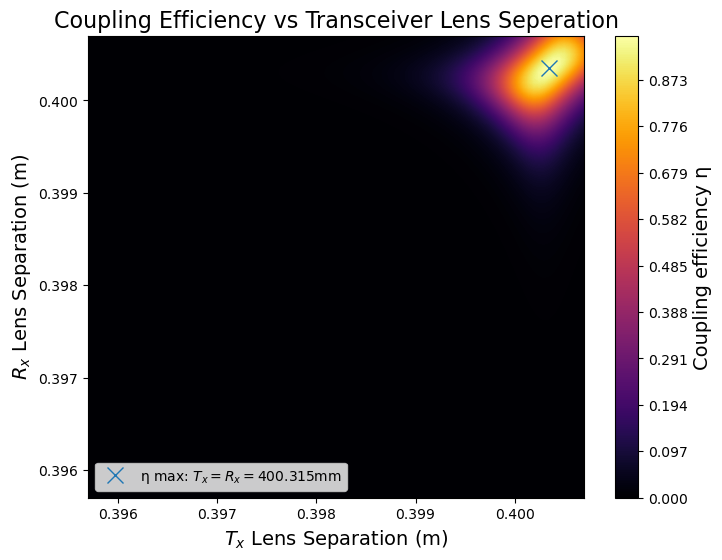

In [59]:
TEL, REC = np.meshgrid(tel_vals, rec_vals)
plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=16)
plt.rc('axes', labelsize=14) 
plt.figure(figsize=(8, 6))

cs = plt.contourf(TEL, REC, ETA, levels=1000, cmap="inferno")
plt.colorbar(cs, label="Coupling efficiency η")

plt.xlabel("$T_{x}$ Lens Separation (m)")
plt.ylabel("$R_{x}$ Lens Separation (m)")
plt.title("Coupling Efficiency vs Transceiver Lens Seperation")

# Mark the best point
idx = np.unravel_index(np.argmax(ETA), ETA.shape)
plt.plot(tel_vals[idx[1]], rec_vals[idx[0]], "x", ms=12, label="η max: $T_{x}=R_{x}=$400.315mm")
plt.legend(loc='lower left')
plt.show()


In [60]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib qt
# --- Convert axes to mm for plotting ---
tel_mm = np.asarray(tel_vals) * 1e3
rec_mm = np.asarray(rec_vals) * 1e3
TEL, REC = np.meshgrid(tel_mm, rec_mm)

# --- Plot style ---
plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=16)
plt.rc('axes', labelsize=14)

fig, ax = plt.subplots(figsize=(8, 6))

# --- Contour plot (force color scale to [0, 1]) ---
levels = np.linspace(0.0, 1.0, 1000)
cs = ax.contourf(TEL, REC, ETA, levels=levels, cmap="inferno", vmin=0.0, vmax=1.0)

# --- Colorbar with ticks every 0.125 ---
cbar = fig.colorbar(cs, ax=ax, label=r"Coupling efficiency $\eta$")
ticks = np.arange(0.0, 1.0 + 0.125, 0.125)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t:g}" for t in ticks])  # 0, 0.125, ..., 1

# --- Labels / title ---
ax.set_xlabel(r"$T_{x}$ Lens Separation (mm)")
ax.set_ylabel(r"$R_{x}$ Lens Separation (mm)")
ax.set_title("Coupling Efficiency vs $T_{x}$/$R_{x}$ Lens Separation")

# --- Mark the best point (in mm) ---
idx = np.unravel_index(np.nanargmax(ETA), ETA.shape)
tx_best = tel_mm[idx[1]]
rx_best = rec_mm[idx[0]]
eta_best = ETA[idx]

ax.plot(tx_best, rx_best, "x", ms=12, mew=2,
        label=rf"$\eta_{{\max}}={eta_best:.3f}$ at $T_x={tx_best:.3f}\,\mathrm{{mm}},\ R_x={rx_best:.3f}\,\mathrm{{mm}}$")

ax.legend(loc="lower left")
plt.show()
#plt.savefig('C5_Finesse_Transceiver_Symmetry.pdf', dpi=300)

In [61]:
import numpy as np
import matplotlib.pyplot as plt
# %matplotlib qt  # keep in your notebook if you want an external window

# --- Convert axes to mm for plotting ---
tel_mm = np.asarray(tel_vals, float) * 1e3
rec_mm = np.asarray(rec_vals, float) * 1e3
TEL, REC = np.meshgrid(tel_mm, rec_mm)

# --- Plot style ---
plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=16)
plt.rc('axes', labelsize=14)

fig, ax = plt.subplots(figsize=(8, 6))

data_square_pct=0.2, 
inset_rect=(0.105, 0.05, 0.6, 0.6)

levels = np.linspace(0.0, 1.0, 11)  # 0, 0.125, ..., 1.0  (8 bands)
cs = ax.contourf(TEL, REC, ETA, levels=levels, cmap="Blues", vmin=0.0, vmax=1.0)

# optional: draw contour lines at the same levels for a "contour plot" look
cl = ax.contour(TEL, REC, ETA, levels=levels, colors="black", linewidths=0.4, alpha=0.35)

# optional: label the contour lines (can be busy; comment out if you prefer)
# ax.clabel(cl, fmt=lambda v: f"{v:g}", fontsize=9)

# --- Colorbar with ticks every 0.125 ---
cbar = fig.colorbar(cs, ax=ax, label=r"$\eta$", ticks=levels)
cbar.set_ticklabels([f"{t:g}" for t in levels])

# --- Labels / title ---
ax.set_xlabel(r"$T_{x}$ (mm)")
ax.set_ylabel(r"$R_{x}$ (mm)")
ax.set_title(r"Coupling Efficiency $\eta$ vs $T_{x}$/$R_{x}$ Lens Separation")

# --- Mark the best point (in mm) ---
idx = np.unravel_index(np.nanargmax(ETA), ETA.shape)
tx_best = float(tel_mm[idx[1]])
rx_best = float(rec_mm[idx[0]])
eta_best = float(ETA[idx])

ax.plot(
    tx_best, rx_best, "x", ms=12, mew=2, color="red",
    label=rf"$\eta_{{\max}}={eta_best:.3f}$ at $T_x={tx_best:.3f}\,\mathrm{{mm}},\ R_x={rx_best:.3f}\,\mathrm{{mm}}$"
)

ax.legend(loc="lower left")

# Save BEFORE show (more reliable across backends)
#fig.savefig("C5_Finesse_Transceiver_Symmetry.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [131]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors, colormaps
import matplotlib.patheffects as pe
from matplotlib.ticker import MaxNLocator, ScalarFormatter, AutoMinorLocator
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from matplotlib.ticker import FuncFormatter

def plot_eta_contours_with_corner_inset(
    tel_vals, rec_vals, ETA,
    *,
    figsize=(8, 6),
    cmap="Blues",  # or "Blues" etc.
    vmin=0.0,
    vmax=1.0,

    # Use linear, discrete contour bands (nice for legend + readability)
    contour_levels=None,  # default -> 0..1 in 0.125 steps

    # Inset geometry:
    data_square_pct=0.30,               # fraction of full span used for square side (e.g., 0.25 = 25%)
    inset_rect=(0.105, 0.05, 0.6, 0.6),# inset placement in axes fraction (x0,y0,w,h)

    # Labeling:
    label_levels=None,  # default -> label every other level

    # Saving:
    savepath=None,
    dpi=300,
):
    # --- Convert axes to mm ---
    tel_mm = np.asarray(tel_vals, float) * 1e3
    rec_mm = np.asarray(rec_vals, float) * 1e3
    TEL, REC = np.meshgrid(tel_mm, rec_mm)

    eta = np.asarray(ETA, float)

    # --- Default levels: 0..1 in 0.125 steps (linear) ---
    if contour_levels is None:
        contour_levels = np.arange(vmin, vmax + 1e-12, 0.125)
    levels = np.array(contour_levels, dtype=float)
    levels = np.unique(levels[np.isfinite(levels)])
    levels.sort()

    if levels.size < 2:
        raise ValueError("Need at least two contour_levels.")
    if levels[0] > vmin:
        levels = np.insert(levels, 0, vmin)
    if levels[-1] < vmax:
        levels = np.append(levels, vmax)

    vmin = float(vmin)
    vmax = float(vmax)

    # label a subset by default (keeps plot clean)
    if label_levels is None:
        # label 0, 0.25, 0.5, 0.75, 1.0 by default if present
        label_levels = [0.0, 0.25, 0.5, 0.75, 1.0]

    # --- Global bounds (mm) ---
    x_all_min, x_all_max = float(tel_mm.min()), float(tel_mm.max())
    y_all_min, y_all_max = float(rec_mm.min()), float(rec_mm.max())
    x_span = x_all_max - x_all_min
    y_span = y_all_max - y_all_min

    if not (0 < data_square_pct <= 1):
        raise ValueError("data_square_pct must be in (0, 1].")

    side = data_square_pct * min(x_span, y_span)

    # --- Inset data window anchored to TOP-RIGHT of main plot ---
    x1, y1 = x_all_max, y_all_max
    x0, y0 = max(x1 - side, x_all_min), max(y1 - side, y_all_min)

    # --- Styling ---
    plt.rcParams.update({'font.size': 10})
    plt.rc('axes', titlesize=16)
    plt.rc('axes', labelsize=14)

    fig, ax = plt.subplots(figsize=figsize)

    # --- Discrete normalization for banded contourf (LINEAR in eta) ---
    cmap_obj = colormaps[cmap].copy()
    # Saturate values outside [vmin, vmax] if present:
    cmap_obj.set_under(cmap_obj(0.0))
    cmap_obj.set_over(cmap_obj(1.0))
    norm = colors.BoundaryNorm(levels, ncolors=cmap_obj.N, clip=False)

    # --- Main plot ---
    cs = ax.contourf(TEL, REC, eta, levels=levels, cmap=cmap_obj, norm=norm, extend="both")
    cl = ax.contour(TEL, REC, eta, levels=levels, colors="black", linewidths=0.5, alpha=0.40)

    # --- Label selected levels with outline ---
    wanted = np.unique(np.asarray(label_levels, float))
    avail = np.asarray(cl.levels, float)
    label_lvls = [lv for lv in wanted if np.any(np.isclose(avail, lv))]
    if label_lvls:
        texts = ax.clabel(cl, levels=label_lvls, fmt=lambda v: f"{v:g}", fontsize=10, inline=True)
        for t in texts:
            t.set_color("black")
            #t.set_path_effects([pe.Stroke(linewidth=1.0, foreground="black"), pe.Normal()])

    # --- Colorbar with 0.125 ticks (linear) ---
    # Contour resolution (fine)
    # contours (and color steps) every 0.05
    levels = np.round(np.arange(vmin, vmax + 1e-9, 0.05), 2)
    
    cs = ax.contourf(TEL, REC, eta, levels=levels, cmap=cmap_obj, norm=norm, extend="both")
    
    # --- Colorbar: major labels every 0.1, minor ticks every 0.05 ---
    cbar = fig.colorbar(cs, ax=ax, extend="both")
    cbar.set_label(r"Coupling efficiency $\eta$")
    
    major = np.round(np.arange(vmin, vmax + 1e-9, 0.1), 2)   # labelled
    minor = np.round(np.arange(vmin, vmax + 1e-9, 0.05), 2)  # tick marks
    
    cbar.set_ticks(major)                 # major ticks (labelled)
    cbar.ax.set_yticks(minor, minor=True) # minor ticks (unlabelled)
    
    # format labels as 0, 0.1, ..., 1 (no trailing zeros like 0.0)
    cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
    
    # make minor ticks visible but subtle
    cbar.ax.tick_params(which="major", length=6, width=1.0)
    cbar.ax.tick_params(which="minor", length=3, width=0.8, labelsize=0)

    ax.set_xlabel(r"$T_{x}$ (mm)")
    ax.set_ylabel(r"$R_{x}$ (mm)")
    ax.set_title(r"Coupling Efficiency $\eta$ vs $T_{x}$/$R_{x}$ Lens Separation")

    # Minor ticks: one minor between majors
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(which="minor", length=3, width=0.6)

    ax.set_xlim(x_all_min, x_all_max)
    ax.set_ylim(y_all_min, y_all_max)

    # --- Best point marker ---
    idx = np.unravel_index(np.nanargmax(eta), eta.shape)
    tx_best = float(tel_mm[idx[1]])
    rx_best = float(rec_mm[idx[0]])
    eta_best = float(eta[idx])

    ax.plot(
        tx_best, rx_best, "x", ms=12, mew=2.8, color="red", zorder=10,
        label=rf"$\eta_{{\max}}={eta_best:.3f}$ at $T_x={tx_best:.3f}\,\mathrm{{mm}},\ R_x={rx_best:.3f}\,\mathrm{{mm}}$"
    )

    # --- Inset (same formatting as your loss version) ---
    axins = ax.inset_axes(inset_rect, zorder=30)
    axins.set_facecolor("white")
    axins.patch.set_alpha(0.95)

    axins.contourf(TEL, REC, eta, levels=levels, cmap=cmap_obj, norm=norm, extend="both")
    cl2 = axins.contour(TEL, REC, eta, levels=levels, colors="black", linewidths=0.4, alpha=0.40)

    if label_lvls:
        texts2 = axins.clabel(cl2, levels=label_lvls, fmt=lambda v: f"{v:g}", fontsize=9, inline=True)
        for t in texts2:
            t.set_color("white")
            t.set_path_effects([pe.Stroke(linewidth=2.0, foreground="black"), pe.Normal()])

    axins.plot(tx_best, rx_best, "x", ms=10, mew=2.4, color="red", zorder=31)

    axins.set_xlim(x0, x1)
    axins.set_ylim(y0, y1)

    # readable inset ticks (same approach)
    axins.xaxis.set_major_locator(MaxNLocator(nbins=6))
    axins.yaxis.set_major_locator(MaxNLocator(nbins=6))
    fmt = ScalarFormatter(useOffset=False)
    fmt.set_scientific(False)
    axins.xaxis.set_major_formatter(fmt)
    axins.yaxis.set_major_formatter(fmt)
    axins.tick_params(labelsize=8)
    axins.grid(True, which='major', alpha=0.7, color='darkgoldenrod', lw=0.6)

    # dashed connectors/rectangle
    mark_inset(
        ax, axins, loc1=2, loc2=4,
        fc="none", ec="0.7", lw=1.2,
        linestyle="--"
    )

    ax.legend(loc="upper left")

    if savepath:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")

    plt.show()
    return fig, ax


#Example:
plot_eta_contours_with_corner_inset(tel_vals, rec_vals, ETA,
                                   data_square_pct=0.30,
                                   savepath="C5_Finesse_Transceiver_Symmetry_eta_contour2.pdf")

(<Figure size 1200x900 with 2 Axes>,
 <Axes: title={'center': 'Coupling Efficiency $\\eta$ vs $T_{x}$/$R_{x}$ Lens Separation'}, xlabel='$T_{x}$ (mm)', ylabel='$R_{x}$ (mm)'>)

In [118]:
import numpy as np
import matplotlib.patheffects as pe

def clabel_prioritise_high_levels(
    ax, contour_set, levels,
    *,
    max_levels=5,              # how many DISTINCT levels to label
    max_per_level=1,           # how many labels per level (usually 1)
    fmt=lambda v: f"{v:g}",
    fontsize=8,
    inline=False,
    inline_spacing=1,
    text_color="white",
    stroke_color="black",
    stroke_width=2.0,
    zorder=40,
):
    levels = np.array(levels, float)
    levels = levels[np.isfinite(levels)]
    levels = np.unique(levels)
    levels.sort()
    levels = levels[::-1]  # high -> low

    placed_texts = []
    labeled_levels = 0

    for lv in levels:
        texts = ax.clabel(
            contour_set,
            levels=[float(lv)],
            fmt=fmt,
            fontsize=fontsize,
            inline=inline,
            inline_spacing=inline_spacing,
        )

        if not texts:
            continue

        # Keep only up to max_per_level labels for this level
        keep = texts[:max_per_level]
        drop = texts[max_per_level:]
        for t in drop:
            t.set_visible(False)

        for t in keep:
            t.set_color(text_color)
            t.set_path_effects([pe.Stroke(linewidth=stroke_width, foreground=stroke_color), pe.Normal()])
            t.set_zorder(zorder)

        placed_texts.extend(keep)
        labeled_levels += 1

        if labeled_levels >= max_levels:
            break

    return placed_texts

In [146]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors, colormaps
import matplotlib.patheffects as pe
from matplotlib.ticker import MaxNLocator, ScalarFormatter, AutoMinorLocator, FuncFormatter
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
    
def plot_eta_contours_with_corner_inset(
    tel_vals, rec_vals, ETA,
    *,
    figsize=(8, 6),
    cmap="Blues",
    vmin=0.0,
    vmax=1.0,
    data_square_pct=0.22,
    inset_rect=(0.104, 0.045, 0.7, 0.7),
    label_levels=(0.1,0.3, 0.5, 0.7, 0.9),     # keep uncluttered
    savepath=None,
    dpi=300,
    legend_loc_main="upper left",
    legend_anchor_main=(0.03, 0.48),
):
    tel_mm = np.asarray(tel_vals, float) * 1e3
    rec_mm = np.asarray(rec_vals, float) * 1e3
    TEL, REC = np.meshgrid(tel_mm, rec_mm)
    eta = np.asarray(ETA, float)

    vmin = float(vmin)
    vmax = float(vmax)

    # --- Global bounds (mm) ---
    x_all_min, x_all_max = float(tel_mm.min()), float(tel_mm.max())
    y_all_min, y_all_max = float(rec_mm.min()), float(rec_mm.max())
    side = float(data_square_pct) * min(x_all_max - x_all_min, y_all_max - y_all_min)

    # inset data window anchored to top-right
    x1, y1 = x_all_max, y_all_max
    x0, y0 = max(x1 - side, x_all_min), max(y1 - side, y_all_min)

    # --- Styling ---
    plt.rcParams.update({'font.size': 10})
    plt.rc('axes', titlesize=16)
    plt.rc('axes', labelsize=14)
    fig, ax = plt.subplots(figsize=figsize)

    # --- ONE consistent set of contour boundaries at 0.05 ---
    levels = np.round(np.arange(vmin, vmax + 1e-9, 0.05), 2)

    cmap_obj = colormaps[cmap].copy()
    cmap_obj.set_under(cmap_obj(0.0))
    cmap_obj.set_over(cmap_obj(1.0))
    norm = colors.BoundaryNorm(levels, ncolors=cmap_obj.N, clip=False)

    # --- Main plot ---
    cs = ax.contourf(TEL, REC, eta, levels=levels, cmap=cmap_obj, norm=norm, extend="both")
    cl = ax.contour(TEL, REC, eta, levels=levels, colors="black", linewidths=0.4, alpha=0.20)

    # labels (subset) with outline
    wanted = np.unique(np.asarray(label_levels, float))
    avail = np.asarray(cl.levels, float)
    label_lvls = [lv for lv in wanted if np.any(np.isclose(avail, lv))]
    if label_lvls:
        texts = ax.clabel(cl, levels=label_lvls, fmt=lambda v: f"{v:g}", fontsize=9, inline=False)
        for t in texts:
            t.set_color("white")
            t.set_path_effects([pe.Stroke(linewidth=1.5, foreground="black"), pe.Normal()])

    # --- Colorbar: major labels 0,0.1,...,1 and minor ticks at 0.05 ---
    cbar = fig.colorbar(cs, ax=ax, extend="both")
    cbar.set_label(r"$\eta$")

    major = np.round(np.arange(vmin, vmax + 1e-9, 0.1), 2)
    cbar.set_ticks(major)                   # majors labelled
    cbar.ax.set_yticks(levels, minor=True)  # minors at every contour boundary

    cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
    cbar.ax.tick_params(which="major", length=6, width=1.0)
    cbar.ax.tick_params(which="minor", length=3, width=0.8)

    # --- Axes labels/title ---
    ax.set_xlabel(r"$T_{x}$ (mm)")
    ax.set_ylabel(r"$R_{x}$ (mm)")
    ax.set_title(r"$T_{x}$/$R_{x}$ Lens Spacing Contour - Coupling $\eta$")

    # Minor ticks on axes
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(which="minor", length=3, width=0.6)

    ax.set_xlim(x_all_min, x_all_max)
    ax.set_ylim(y_all_min, y_all_max)

    # --- Best point marker ---
    idx = np.unravel_index(np.nanargmax(eta), eta.shape)
    tx_best = float(tel_mm[idx[1]])
    rx_best = float(rec_mm[idx[0]])
    eta_best = float(eta[idx])
    ax.plot(tx_best, rx_best, "x", ms=12, mew=2.8, color="red", zorder=10,
            label=rf"$\eta_{{\max}}={eta_best:.3f}$, $T_x=R_x={rx_best:.3f}\,\mathrm{{mm}}$")

    # --- Inset ---
    axins = ax.inset_axes(inset_rect, zorder=30)
    axins.set_facecolor("white")
    axins.patch.set_alpha(0.95)
    
    axins.contourf(TEL, REC, eta, levels=levels, cmap=cmap_obj, norm=norm, extend="both")
    
    # 1) faint contours for context (all levels)
    cl2 = axins.contour(
        TEL, REC, eta,
        levels=levels,
        colors="black",
        linewidths=0.2,
        alpha=0.10
    )
    
    # 2) highlighted contours ONLY where you label (thicker + more opaque)
    if label_lvls:
        cl2_hi = axins.contour(
            TEL, REC, eta,
            levels=label_lvls,
            colors="black",
            linewidths=0.8,
            alpha=0.55,
            zorder=35
        )
    
        # Prioritise high-value labels (e.g. label at most 4, high->low)
        _ = clabel_prioritise_high_levels(
            axins, cl2_hi, label_lvls,
            max_levels=6,      # e.g. label up to 5 different levels
            max_per_level=6,   # one label per level
            fmt=lambda v: f"{v:g}",
            fontsize=9.5,
            inline=False,
            inline_spacing=0.5,
            zorder=40
        )
    axins.plot(tx_best, rx_best, "x", ms=10, mew=2.4, color="red", zorder=31)
    axins.set_xlim(x0, x1)
    axins.set_ylim(y0, y1)

    axins.xaxis.set_major_locator(MaxNLocator(nbins=6))
    axins.yaxis.set_major_locator(MaxNLocator(nbins=6))
    fmt = ScalarFormatter(useOffset=False)
    fmt.set_scientific(False)
    axins.xaxis.set_major_formatter(fmt)
    axins.yaxis.set_major_formatter(fmt)
    
    axins.tick_params(labelsize=8)
    axins.grid(True, which='major', alpha=0.7, color='grey', lw=0.75)

    mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.7", lw=0.9, linestyle="--")
    ax.legend(loc=legend_loc_main, bbox_to_anchor=legend_anchor_main,borderaxespad=0.15,borderpad=0.2)

    if savepath:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")

    plt.show()
    return fig, ax
plot_eta_contours_with_corner_inset(tel_vals, rec_vals, ETA,
                                   data_square_pct=0.24,
                                   savepath="C5_Finesse_Transceiver_Symmetry_eta_contour2.pdf",legend_anchor_main=(-0.00215, 1.0025))

(<Figure size 1200x900 with 2 Axes>,
 <Axes: title={'center': '$T_{x}$/$R_{x}$ Lens Spacing Contour - Coupling $\\eta$'}, xlabel='$T_{x}$ (mm)', ylabel='$R_{x}$ (mm)'>)

In [103]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

def plot_coupling_loss_db(
    tel_vals, rec_vals, ETA,
    *,
    figsize=(8, 6),
    cmap="inferno_r",          # good perceptual sequential map for "loss"
    gamma=0.6,             # <1 expands low-loss region (non-linear)
    eps=1e-12,             # protects log10(0)
    vmax_db=None,          # optionally cap max loss shown (e.g. 30)
):
    # --- Convert axes to mm ---
    tel_mm = np.asarray(tel_vals) * 1e3
    rec_mm = np.asarray(rec_vals) * 1e3
    TEL, REC = np.meshgrid(tel_mm, rec_mm)

    # --- Convert coupling efficiency to dB loss ---
    eta = np.asarray(ETA, float)
    eta_clip = np.clip(eta, eps, 1.0)          # eta in (0,1]
    loss_db = -10.0 * np.log10(eta_clip)       # 0 dB = no loss (eta=1)

    # --- Choose plotting range for loss ---
    vmin = 0.0
    if vmax_db is None:
        # robust cap so one tiny eta value doesn't blow the scale
        vmax = float(np.nanpercentile(loss_db, 99.5))
        vmax = max(vmax, 1.0)
    else:
        vmax = float(vmax_db)

    # --- Styling ---
    plt.rcParams.update({'font.size': 10})
    plt.rc('axes', titlesize=16)
    plt.rc('axes', labelsize=14)

    fig, ax = plt.subplots(figsize=figsize)

    # --- Non-linear colormap normalization ---
    # PowerNorm with gamma<1 spreads the low end (low loss) to show detail near best coupling
    norm = colors.PowerNorm(gamma=gamma, vmin=vmin, vmax=vmax)

    # --- Filled contours ---
    levels = np.linspace(vmin, vmax, 600)
    cs = ax.contourf(TEL, REC, loss_db, levels=levels, cmap=cmap, norm=norm)

    # --- Colorbar with dB ticks ---
    # pick "nice" ticks within range
    candidate_ticks = np.array([0, 0.5, 1, 2, 3, 4, 5, 7.5, 10, 15, 20, 25, 30, 40, 50], float)
    ticks = candidate_ticks[(candidate_ticks >= vmin) & (candidate_ticks <= vmax)]
    cbar = fig.colorbar(cs, ax=ax, ticks=ticks)
    cbar.set_label(r"Loss (dB),  $-10\log_{10}(\eta)$")

    # --- Labels / title ---
    ax.set_xlabel(r"$T_{x}$ Lens Separation (mm)")
    ax.set_ylabel(r"$R_{x}$ Lens Separation (mm)")
    ax.set_title("Coupling Loss vs Transceiver Lens Separation")

    # --- Mark best point (max ETA = min loss) ---
    idx = np.unravel_index(np.nanargmax(eta), eta.shape)
    tx_best = tel_mm[idx[1]]
    rx_best = rec_mm[idx[0]]
    eta_best = eta[idx]
    loss_best = -10.0 * np.log10(np.clip(eta_best, eps, 1.0))

    ax.plot(tx_best, rx_best, "x", ms=12, mew=2,
        label=rf"$\eta_{{\max}}={eta_best:.3f}$ at $T_x={tx_best:.3f}\,\mathrm{{mm}},\ R_x={rx_best:.3f}\,\mathrm{{mm}}$")
    

    ax.set_xlim(tel_mm[0], tel_mm[-1])
    ax.set_ylim(rec_mm[0], rec_mm[-1])
    ax.legend(loc="lower left")
    plt.show()


# --- Example call ---
plot_coupling_loss_db(tel_vals, rec_vals, ETA, gamma=0.6, vmax_db=30)

In [84]:
plot_coupling_loss_db_contours(tel_vals, rec_vals, ETA, gamma=0.6, vmax_db=30,contour_levels=(0, 0.5, 1, 2, 3, 5, 10, 20, 30))

In [87]:
plot_coupling_loss_db_contours_with_inset(tel_vals, rec_vals, ETA, gamma=0.6, vmax_db=30,contour_levels=(0, 0.5, 1, 2, 3, 5, 10, 20, 30))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors, colormaps
import matplotlib.patheffects as pe
from matplotlib.ticker import MaxNLocator, ScalarFormatter
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from matplotlib.ticker import AutoMinorLocator

def plot_coupling_loss_db_contours_with_corner_inset(
    tel_vals, rec_vals, ETA,
    *,
    figsize=(8, 6),
    cmap="Blues_r",
    eps=1e-12,
    vmax_db=30,
    contour_levels=(0, 1, 2, 3, 5, 10, 15, 30, 45),
    legend_loc_main="upper left",
    legend_anchor_main=(0.03, 0.48),
    # Inset geometry:
    data_square_pct=0.22,               # fraction of full span used for square side (e.g., 0.25 = 25%)
    inset_rect=(0.105, 0.05, 0.55, 0.55),# inset placement in axes fraction (x0,y0,w,h)

    # Labeling:
    label_levels=(1, 3, 5, 10, 15, 30, 45),
):
    """
    Main: discrete contour bands of loss(dB) = -10log10(eta), axes in mm.
    Inset: zoom window is a square in data-coordinates whose TOP-RIGHT corner matches
           the TOP-RIGHT corner of the main plot. Square side = data_square_pct * min(full_x_span, full_y_span).
    """

    # --- Convert axes to mm ---
    tel_mm = np.asarray(tel_vals, float) * 1e3
    rec_mm = np.asarray(rec_vals, float) * 1e3
    TEL, REC = np.meshgrid(tel_mm, rec_mm)

    # --- Convert to dB loss ---
    eta = np.asarray(ETA, float)
    eta_clip = np.clip(eta, eps, 1.0)
    loss_db = -10.0 * np.log10(eta_clip)

    # --- Levels sanitize + ensure vmax_db included ---
    levels = np.array(contour_levels, dtype=float)
    levels = np.unique(levels[np.isfinite(levels)])
    levels.sort()
    if levels.size < 2:
        raise ValueError("Need at least two contour_levels.")

    vmax_db = float(vmax_db)
    if vmax_db < levels[-1]:
        levels = levels[levels <= vmax_db]
        if levels.size < 2:
            levels = np.array([0.0, vmax_db])
        elif levels[-1] != vmax_db:
            levels = np.append(levels, vmax_db)
    elif vmax_db > levels[-1]:
        levels = np.append(levels, vmax_db)

    # --- Global data bounds (mm) ---
    x_all_min, x_all_max = float(tel_mm.min()), float(tel_mm.max())
    y_all_min, y_all_max = float(rec_mm.min()), float(rec_mm.max())
    x_span = x_all_max - x_all_min
    y_span = y_all_max - y_all_min

    if not (0 < data_square_pct <= 1):
        raise ValueError("data_square_pct must be in (0, 1].")

    # side length based on smaller span to ensure square fits
    side = data_square_pct * min(x_span, y_span)

    # --- Inset data window anchored to TOP-RIGHT corner of the full plot ---
    x1 = x_all_max
    y1 = y_all_max
    x0 = x1 - side
    y0 = y1 - side

    # Clamp (should already fit, but just in case)
    x0 = max(x0, x_all_min)
    y0 = max(y0, y_all_min)

    # --- Styling ---
    plt.rcParams.update({'font.size': 10})
    plt.rc('axes', titlesize=16)
    plt.rc('axes', labelsize=14)

    fig, ax = plt.subplots(figsize=figsize)

    # --- Discrete normalization for banded contourf ---
    cmap_obj = colormaps[cmap].copy()
    cmap_obj.set_over(cmap_obj(1.0))  # overflow -> darkest for *_r
    norm = colors.BoundaryNorm(levels, ncolors=cmap_obj.N, clip=False)

    # --- Main plot ---
    cs = ax.contourf(TEL, REC, loss_db, levels=levels, cmap=cmap_obj, norm=norm, extend="max")
    cl = ax.contour(TEL, REC, loss_db, levels=levels, colors="black", linewidths=0.45, alpha=0.70)

    # Label selected levels with outline
    wanted = np.unique(np.asarray(label_levels, float))
    avail = np.asarray(cl.levels, float)
    label_lvls = [lv for lv in wanted if np.any(np.isclose(avail, lv))]
    if label_lvls:
        texts = ax.clabel(cl, levels=label_lvls, fmt=lambda v: f"{v:g} dB", fontsize=10, inline=False)
        for t in texts:
            t.set_color("white")
            t.set_path_effects([pe.Stroke(linewidth=1.5, foreground="black"), pe.Normal()])


    cbar = fig.colorbar(cs, ax=ax, ticks=levels, extend="max")
    cbar.set_label(r"$L(\eta)\,$dB")

    ax.set_xlabel(r"$T_{x}$ (mm)")
    ax.set_ylabel(r"$R_{x}$ (mm)")
    ax.set_title(r"$T_{x}$/$R_{x}$ Lens Spacing Contour - Loss $L(\eta)$")
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(which="minor", length=3, width=0.6)
    ax.set_xlim(x_all_min, x_all_max)
    ax.set_ylim(y_all_min, y_all_max)

    # --- Best point marker ---
    idx = np.unravel_index(np.nanargmax(eta), eta.shape)
    tx_best = float(tel_mm[idx[1]])
    rx_best = float(rec_mm[idx[0]])
    loss_db_best = -10.0 * np.log10(eta_best)
    ax.plot(tx_best, rx_best, "x", ms=10.5, mew=2.8, color="red", zorder=10,
            label=rf"$\!L_{{\min}}(\eta)={loss_db_best:.3f}$dB, $\!T_x=R_x={rx_best:.3f}\,\mathrm{{mm}}$")

    # --- Inset (placed on figure), zooming to the fixed top-right data window ---
    axins = ax.inset_axes(inset_rect, zorder=30)
    axins.set_facecolor("white")
    axins.patch.set_alpha(0.95)

    axins.contourf(TEL, REC, loss_db, levels=levels, cmap=cmap_obj, norm=norm, extend="max")
    cl2 = axins.contour(TEL, REC, loss_db, levels=levels, colors="black", linewidths=0.65, alpha=0.75)

    # Inset labels (fewer is usually better)
    inset_label_lvls = [lv for lv in label_lvls if lv <= levels[-1]]
    if inset_label_lvls:
        texts2 = axins.clabel(cl2, levels=inset_label_lvls, fmt=lambda v: f"{v:g} dB", fontsize=9, inline=False)
        for t in texts2:
            t.set_color("white")
            t.set_path_effects([pe.Stroke(linewidth=2.0, foreground="black"), pe.Normal()])

    axins.plot(tx_best, rx_best, "x", ms=9, mew=2.4, color="red", zorder=31)

    axins.set_xlim(x0, x1)
    axins.set_ylim(y0, y1)

    # readable inset ticks
    axins.xaxis.set_major_locator(MaxNLocator(nbins=6))
    axins.yaxis.set_major_locator(MaxNLocator(nbins=6))
    fmt = ScalarFormatter(useOffset=False)
    fmt.set_scientific(False)
    axins.xaxis.set_major_formatter(fmt)
    axins.yaxis.set_major_formatter(fmt)
    axins.tick_params(labelsize=8)
    axins.grid(True, which='major', alpha=0.7, color='grey', lw=0.75)

    # connectors/rectangle
    mark_inset(ax, axins, loc1=2, loc2=4,
               fc="none", ec="0.7", lw=0.9,
               linestyle="--")    
    ax.legend(loc=legend_loc_main, bbox_to_anchor=legend_anchor_main,borderaxespad=0.15,borderpad=0.2)

    plt.show()


# Example:
plot_coupling_loss_db_contours_with_corner_inset(tel_vals, rec_vals, ETA, data_square_pct=0.25, vmax_db=45, legend_anchor_main=(-0.00225, 1.0025))
plt.savefig('C5_Finesse_Transceiver_Symmetry_db_contour2.pdf', dpi=300, bbox_inches="tight")

In [72]:
tel_vals

array([0.3957    , 0.39582821, 0.39595641, 0.39608462, 0.39621282,
       0.39634103, 0.39646923, 0.39659744, 0.39672564, 0.39685385,
       0.39698205, 0.39711026, 0.39723846, 0.39736667, 0.39749487,
       0.39762308, 0.39775128, 0.39787949, 0.39800769, 0.3981359 ,
       0.3982641 , 0.39839231, 0.39852051, 0.39864872, 0.39877692,
       0.39890513, 0.39903333, 0.39916154, 0.39928974, 0.39941795,
       0.39954615, 0.39967436, 0.39980256, 0.39993077, 0.40005897,
       0.40018718, 0.40031538, 0.40044359, 0.40057179, 0.4007    ])

In [ ]:
rec_vals

In [75]:
print(ETA)

[[2.94019741e-08 3.28716676e-08 3.68676316e-08 ... 4.31531636e-04
  2.70853552e-04 1.47720414e-04]
 [3.28726184e-08 3.67525124e-08 4.12209925e-08 ... 4.80649710e-04
  3.01372157e-04 1.64340132e-04]
 [3.68698255e-08 4.12222531e-08 4.62350670e-08 ... 5.36921473e-04
  3.36293632e-04 1.83355856e-04]
 ...
 [4.31109873e-04 4.80167090e-04 5.36367228e-04 ... 9.48642160e-01
  8.65714594e-01 7.03365659e-01]
 [2.70591416e-04 3.01072549e-04 3.35949980e-04 ... 8.65327807e-01
  8.38040720e-01 6.99583532e-01]
 [1.47577667e-04 1.64176995e-04 1.83168752e-04 ... 7.02754123e-01
  6.99583532e-01 5.79329826e-01]]


In [450]:
imax = np.unravel_index(np.argmax(ETA), ETA.shape)

tel_best = tel_vals[imax[1]]
rec_best = rec_vals[imax[0]]
eta_best = ETA[imax]

print("Maximum Gaussian coupling found:")
print(f"  η_max = {eta_best:.6f}")
print(f"  s_l1_l2 (tel) = {tel_best:.6f} m")
print(f"  s_l3_l4 (rec) = {rec_best:.6f} m")


Maximum Gaussian coupling found:
  η_max = 0.999802
  s_l1_l2 (tel) = 0.400043 m
  s_l3_l4 (rec) = 0.399993 m


In [42]:
import numpy as np
from finesse.knm import Map
from finesse.utilities.maps import circular_aperture

# ----------------------------
# Constants
# ----------------------------
LAMBDA = 1550e-9  # meters
INCH   = 0.0254

# Pupil diameters you used in Zemax:
#  - AC254 (1") : 21 mm diameter  -> 10.5 mm radius
#  - ACT508 (2"): 49 mm diameter  -> 24.5 mm radius
R_ZEMAX_AC254  = 0.021 / 2   # 0.0105 m
R_ZEMAX_ACT508 = 0.049 / 2   # 0.0245 m

# ----------------------------
# Zemax Fringe m=0 polynomials (exactly as printed)
# ----------------------------
def fringe_m0_poly(j, p):
    """
    Zemax Fringe Zernike polynomials for m=0 terms (as printed in your report).
    p is normalized radius in [0,1].
    """
    p2 = p*p
    if j == 1:   # 1
        return np.ones_like(p)
    if j == 4:   # (2p^2 - 1)
        return (2*p2 - 1)
    if j == 9:   # (6p^4 - 6p^2 + 1)
        return (6*p2**2 - 6*p2 + 1)
    if j == 16:  # (20p^6 - 30p^4 + 12p^2 - 1)
        return (20*p2**3 - 30*p2**2 + 12*p2 - 1)
    if j == 25:  # (70p^8 - 140p^6 + 90p^4 - 20p^2 + 1)
        return (70*p2**4 - 140*p2**3 + 90*p2**2 - 20*p2 + 1)
    if j == 36:  # (252p^10 - 630p^8 + 560p^6 - 210p^4 + 30p^2 - 1)
        return (252*p2**5 - 630*p2**4 + 560*p2**3 - 210*p2**2 + 30*p2 - 1)
    if j == 37:  # (924p^12 - 2772p^10 + 3150p^8 - 1680p^6 + 420p^4 - 42p^2 + 1)
        return (924*p2**6 - 2772*p2**5 + 3150*p2**4 - 1680*p2**3 + 420*p2**2 - 42*p2 + 1)
    raise ValueError(f"Unsupported Fringe term Z{j} for this helper (add it if needed).")

def opd_from_fringe_m0(x, y, R_zemax_m, coeff_waves, wavelength=LAMBDA):
    """
    Build OPD(x,y) in meters from Zemax Fringe coefficients (waves) for m=0 terms.
    R_zemax_m is the pupil radius used in Zemax (meters).
    """
    X, Y = np.meshgrid(x, y)
    r = np.sqrt(X**2 + Y**2)
    p = np.clip(r / float(R_zemax_m), 0.0, 1.0)

    opd_waves = np.zeros_like(p)
    for j, aj in coeff_waves.items():
        opd_waves += float(aj) * fringe_m0_poly(int(j), p)

    return opd_waves * float(wavelength)  # waves -> meters

def make_aperture_opd_map_from_fringe(
    diameter_inch,
    R_zemax_m,
    coeff_waves,
    wavelength=LAMBDA,
    grid_pad=1.25,
    N=512,
    remove_piston=True,
    remove_defocus=True,
    remove_spherical=True,   # <-- NEW: remove Z9
):
    """
    Returns a finesse.knm.Map with:
      - amplitude: hard circular aperture (diameter_inch)
      - opd: Zemax Fringe OPD in meters
    """
    coeff = dict(coeff_waves)

    # Strip low-order terms
    if remove_piston and 1 in coeff:
        coeff[1] = 0.0
    if remove_defocus and 4 in coeff:
        coeff[4] = 0.0
    if remove_spherical and 9 in coeff:
        coeff[9] = 0.0

    # Grid sized to the physical aperture (NOT the Zemax pupil)
    R_ap = 0.5 * diameter_inch * INCH
    half_width = grid_pad * R_ap

    x = np.linspace(-half_width, half_width, N)
    y = np.linspace(-half_width, half_width, N)

    amp = circular_aperture(x, y, R_ap)
    opd = opd_from_fringe_m0(x, y, R_zemax_m, coeff, wavelength=wavelength)

    opd = np.where(amp > 0, opd, 0.0)
    return Map(x, y, amplitude=amp, opd=opd)

# ----------------------------
# Coefficient dicts from your pastes (waves @ 1550 nm)
# ----------------------------

# Lens 1: AC254-100-C, Surface 3 (your earlier paste)
FRINGE_L1_AC254 = {
    1:   0.24339474,
    4:   0.32950600,
    9:   0.06028224,
    16: -0.02751208,
    25: -0.00177152,
    36: -0.00009286,
    37: -0.00000461,
}

# Lens 4: AC254-100-C, Surface 4 (your lens 4 paste)
FRINGE_L4_AC254 = {
    1:   7.13091357,
    4:  10.65468897,
    9:   3.49207742,
    16: -0.03476490,
    25: -0.00317787,
    36: -0.00011406,
    37: -0.00000318,
}

# Lens 2: ACT508-300-C, Surface 3 (your lens 2 paste)
FRINGE_L2_ACT508 = {
    1:   1.97021528,
    4:   2.95055426,
    9:   0.97708163,
    16: -0.00331683,
    25: -0.00006010,
    36: -0.00000064,
    # 37: 0.0  (not included)
}

# Lens 3: ACT508-300-C, Surface 3 (your earlier ACT508 paste with small WFE)
FRINGE_L3_ACT508 = {
    1:  -0.05814704,
    4:  -0.09416934,
    9:  -0.04079239,
    16: -0.00487611,
    25: -0.00010834,
    36: -0.00000238,
    37: -0.00000005,
}

# ----------------------------
# Build and attach maps
# (Assumes lens_1...lens_4 already exist in your notebook)
# ----------------------------

# Lens clear apertures per your requirement:
#   lens 1: 1 inch
#   lens 2: 2 inch
#   lens 3: 2 inch
#   lens 4: 1 inch

lens_1.OPD_map = make_aperture_opd_map_from_fringe(
    diameter_inch=1.0,
    R_zemax_m=R_ZEMAX_AC254,
    coeff_waves=FRINGE_L1_AC254,
    wavelength=1550e-9,
    N=512,
    grid_pad=1.25,
    remove_piston=True,
    remove_defocus=True,   # recommended for thin-lens geometry
)

lens_2.OPD_map = make_aperture_opd_map_from_fringe(
    diameter_inch=2.0,
    R_zemax_m=R_ZEMAX_ACT508,
    coeff_waves=FRINGE_L2_ACT508,
    wavelength=1550e-9,
    N=512,
    grid_pad=1.25,
    remove_piston=True,
    remove_defocus=True,
)

lens_3.OPD_map = make_aperture_opd_map_from_fringe(
    diameter_inch=2.0,
    R_zemax_m=R_ZEMAX_ACT508,
    coeff_waves=FRINGE_L3_ACT508,
    wavelength=1550e-9,
    N=512,
    grid_pad=1.25,
    remove_piston=True,
    remove_defocus=True,
)

lens_4.OPD_map = make_aperture_opd_map_from_fringe(
    diameter_inch=1.0,
    R_zemax_m=R_ZEMAX_AC254,
    coeff_waves=FRINGE_L4_AC254,
    wavelength=1550e-9,
    N=512,
    grid_pad=1.25,
    remove_piston=True,
    remove_defocus=True,
)

print("Attached aperture+OPD maps to lens_1..lens_4 (piston+defocus removed).")


Attached aperture+OPD maps to lens_1..lens_4 (piston+defocus removed).


In [46]:
def opd_stats_from_coeffs(R_zemax_m, coeff_waves, remove=(1,4,9), N=512):
    R = float(R_zemax_m)
    x = np.linspace(-R, R, N)
    y = np.linspace(-R, R, N)
    X, Y = np.meshgrid(x, y)
    r = np.sqrt(X**2 + Y**2)
    mask = r <= R
    p = np.clip(r / R, 0.0, 1.0)

    coeff = dict(coeff_waves)
    for k in remove:
        if k in coeff:
            coeff[k] = 0.0

    opd_waves = np.zeros_like(p)
    for j, aj in coeff.items():
        opd_waves += float(aj) * fringe_m0_poly(int(j), p)

    opd_waves = opd_waves[mask]
    opd_waves -= opd_waves.mean()

    rms = float(np.sqrt(np.mean(opd_waves**2)))
    pv  = float(opd_waves.max() - opd_waves.min())
    return rms, pv


In [48]:
print("L1:", opd_stats_from_coeffs(R_ZEMAX_AC254,  FRINGE_L1_AC254))
print("L2:", opd_stats_from_coeffs(R_ZEMAX_ACT508, FRINGE_L2_ACT508))
print("L3:", opd_stats_from_coeffs(R_ZEMAX_ACT508, FRINGE_L3_ACT508))
print("L4:", opd_stats_from_coeffs(R_ZEMAX_AC254,  FRINGE_L4_AC254))


L1: (0.010402760519388479, 0.055186434709466034)
L2: (0.0012524377386624937, 0.006632287996663107)
L3: (0.001841321749916624, 0.00975305845041791)
L4: (0.01316573211386886, 0.06972737089101272)


In [49]:
# ============================
# FULL FINESSE3 HOM NOTEBOOK SCRIPT
# ============================

import time
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import FloatSlider
from IPython.display import display

import finesse
from finesse.components import Space, Lens, Laser, Nothing, Gauss
from finesse.knm import Map
from finesse.utilities.maps import circular_aperture
from finesse.detectors import PowerDetector, AmplitudeDetector


# ----------------------------
# Constants
# ----------------------------
LAMBDA = 1550e-9  # meters
INCH   = 0.0254

# Pupil diameters used in Zemax exports:
#  - AC254 (1") : 21 mm diameter  -> 10.5 mm radius
#  - ACT508 (2"): 49 mm diameter  -> 24.5 mm radius
R_ZEMAX_AC254  = 0.021 / 2   # 0.0105 m
R_ZEMAX_ACT508 = 0.049 / 2   # 0.0245 m


# ----------------------------
# Zemax Fringe m=0 polynomials (exactly as printed)
# ----------------------------
def fringe_m0_poly(j, p):
    """
    Zemax Fringe Zernike polynomials for m=0 terms (as printed).
    p is normalized radius in [0,1].
    """
    p2 = p*p
    if j == 1:   # 1
        return np.ones_like(p)
    if j == 4:   # (2p^2 - 1)
        return (2*p2 - 1)
    if j == 9:   # (6p^4 - 6p^2 + 1)
        return (6*p2**2 - 6*p2 + 1)
    if j == 16:  # (20p^6 - 30p^4 + 12p^2 - 1)
        return (20*p2**3 - 30*p2**2 + 12*p2 - 1)
    if j == 25:  # (70p^8 - 140p^6 + 90p^4 - 20p^2 + 1)
        return (70*p2**4 - 140*p2**3 + 90*p2**2 - 20*p2 + 1)
    if j == 36:  # (252p^10 - 630p^8 + 560p^6 - 210p^4 + 30p^2 - 1)
        return (252*p2**5 - 630*p2**4 + 560*p2**3 - 210*p2**2 + 30*p2 - 1)
    if j == 37:  # (924p^12 - 2772p^10 + 3150p^8 - 1680p^6 + 420p^4 - 42p^2 + 1)
        return (924*p2**6 - 2772*p2**5 + 3150*p2**4 - 1680*p2**3 + 420*p2**2 - 42*p2 + 1)
    raise ValueError(f"Unsupported Fringe term Z{j}. Add it if needed.")


def opd_from_fringe_m0(x, y, R_zemax_m, coeff_waves, wavelength=LAMBDA):
    """
    Build OPD(x,y) [meters] from Zemax Fringe coefficients [waves] for m=0 terms.
    R_zemax_m is the pupil radius used in Zemax.
    """
    X, Y = np.meshgrid(x, y)
    r = np.sqrt(X**2 + Y**2)
    p = np.clip(r / float(R_zemax_m), 0.0, 1.0)

    opd_waves = np.zeros_like(p)
    for j, aj in coeff_waves.items():
        opd_waves += float(aj) * fringe_m0_poly(int(j), p)

    return opd_waves * float(wavelength)  # waves -> meters


def make_aperture_opd_map_from_fringe(
    diameter_inch,
    R_zemax_m,
    coeff_waves,
    wavelength=LAMBDA,
    grid_pad=1.25,
    N=512,
    remove_terms=(1, 4, 9)   # remove piston, defocus, primary spherical-like
):
    """
    Returns a finesse.knm.Map with:
      - amplitude: hard circular aperture (diameter_inch)
      - opd: OPD in meters built from Zemax Fringe coefficients, with selected terms removed
    """
    coeff = dict(coeff_waves)
    for k in remove_terms:
        if k in coeff:
            coeff[k] = 0.0

    # Grid sized to the PHYSICAL aperture
    R_ap = 0.5 * diameter_inch * INCH
    half_width = grid_pad * R_ap

    x = np.linspace(-half_width, half_width, N)
    y = np.linspace(-half_width, half_width, N)

    amp = circular_aperture(x, y, R_ap)
    opd = opd_from_fringe_m0(x, y, R_zemax_m, coeff, wavelength=wavelength)

    # outside aperture, kill phase (amplitude already 0, but keep opd clean)
    opd = np.where(amp > 0, opd, 0.0)

    return Map(x, y, amplitude=amp, opd=opd)


# ----------------------------
# Fringe coefficient dicts (waves @ 1550 nm)
# ----------------------------
FRINGE_L1_AC254 = {
    1:   0.24339474,
    4:   0.32950600,
    9:   0.06028224,
    16: -0.02751208,
    25: -0.00177152,
    36: -0.00009286,
    37: -0.00000461,
}

FRINGE_L2_ACT508 = {
    1:   1.97021528,
    4:   2.95055426,
    9:   0.97708163,
    16: -0.00331683,
    25: -0.00006010,
    36: -0.00000064,
}

FRINGE_L3_ACT508 = {
    1:  -0.05814704,
    4:  -0.09416934,
    9:  -0.04079239,
    16: -0.00487611,
    25: -0.00010834,
    36: -0.00000238,
    37: -0.00000005,
}

FRINGE_L4_AC254 = {
    1:   7.13091357,
    4:  10.65468897,
    9:   3.49207742,
    16: -0.03476490,
    25: -0.00317787,
    36: -0.00011406,
    37: -0.00000318,
}


# ----------------------------
# Model builder
# ----------------------------
def setup_model(f1, f2, f3, f4, d1, d2, d3, d4, d5, maxtem=10, visualise=False):
    """
    laser -> lens1 -> lens2 -> lens3 -> lens4 -> target

    d1: laser->lens1
    d2: lens1->lens2   (slider tel)
    d4: lens2->lens3   (long space)
    d5: lens3->lens4   (slider rec)
    d3: lens4->target
    """
    M = finesse.model.Model()
    M.lambda0 = LAMBDA

    # Enable HOM basis
    M.modes(maxtem=maxtem)

    # Laser: keep carrier frequency at default; we reference laser_1550.f in detector
    laser_1550 = Laser("laser_1550", P=1)
    M.add(laser_1550)

    lens_1 = Lens("lens_1", f=f1)
    lens_2 = Lens("lens_2", f=f2)
    lens_3 = Lens("lens_3", f=f3)
    lens_4 = Lens("lens_4", f=f4)
    M.add([lens_1, lens_2, lens_3, lens_4])

    # Attach aperture + OPD maps (remove Z1,Z4,Z9)
    lens_1.OPD_map = make_aperture_opd_map_from_fringe(1.0, R_ZEMAX_AC254,  FRINGE_L1_AC254)
    lens_2.OPD_map = make_aperture_opd_map_from_fringe(2.0, R_ZEMAX_ACT508, FRINGE_L2_ACT508)
    lens_3.OPD_map = make_aperture_opd_map_from_fringe(2.0, R_ZEMAX_ACT508, FRINGE_L3_ACT508)
    lens_4.OPD_map = make_aperture_opd_map_from_fringe(1.0, R_ZEMAX_AC254,  FRINGE_L4_AC254)

    target = Nothing("target")
    M.add(target)

    # Spaces
    s_L_l1  = Space("s_L_l1",  portA=laser_1550.p1, portB=lens_1.p1, L=d1)
    s_l1_l2 = Space("s_l1_l2", portA=lens_1.p2,     portB=lens_2.p1, L=d2)  # slider tel
    s_l2_l3 = Space("s_l2_l3", portA=lens_2.p2,     portB=lens_3.p1, L=d4)  # long
    s_l3_l4 = Space("s_l3_l4", portA=lens_3.p2,     portB=lens_4.p1, L=d5)  # slider rec
    s_l4_t  = Space("s_l4_t",  portA=lens_4.p2,     portB=target.p1, L=d3)

    M.add([s_L_l1, s_l1_l2, s_l2_l3, s_l3_l4, s_l4_t])

    # Define input Gaussian basis at laser output (launched TEM00)
    g_in = Gauss("g_in", laser_1550.p1.o, w0=3.5e-3, z=37.20e-3)
    M.add(g_in)

    # Define reference Gaussian basis at target plane (defines what "HG00" means there)
    g_ref = Gauss("g_ref", target.p1.i, w0=3.5e-3, z=37.20e-3)
    M.add(g_ref)

    # Detectors at target
    M.add(PowerDetector("Ptot", target.p1.i))

    # IMPORTANT: specify the carrier frequency explicitly to avoid "no bin at 0 Hz"
    M.add(AmplitudeDetector("E00", target.p1.i, laser_1550.f, n=0, m=0))

    if visualise:
        print(M.component_tree())
        M.plot_graph(arrows=True, graphviz=False, layout="spiral")

    return (M, laser_1550, target, lens_1, lens_2, lens_3, lens_4,
            s_L_l1, s_l1_l2, s_l2_l3, s_l3_l4, s_l4_t)


# ----------------------------
# Update plot + coupling
# ----------------------------
def update_plot(tel_zs_value, rec_zs_value):
    plt.close("all")

    # Update variable distances
    if hasattr(s_l1_l2.L, "value"):
        s_l1_l2.L.value = float(tel_zs_value)
        s_l3_l4.L.value = float(rec_zs_value)
    else:
        s_l1_l2.L = float(tel_zs_value)
        s_l3_l4.L = float(rec_zs_value)

    # Run a single-point simulation
    sol = M.run("noxaxis()")

    # Read detectors
    Ptot = float(np.atleast_1d(sol["Ptot"])[0])
    E00  = np.atleast_1d(sol["E00"])[0]
    E00  = complex(E00)

    # TEM00 coupling fraction (power fraction in HG00 at target)
    eta = 0.0 if Ptot <= 0 else (abs(E00)**2 / Ptot)
    eta = max(0.0, min(1.0, eta))  # clamp safely

    # Simple diagnostic plots (fast)
    fig = plt.figure(figsize=(12, 3.8), constrained_layout=True)
    gs = fig.add_gridspec(1, 2)

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])

    ax1.axis("off")
    ax1.text(0.0, 0.85, f"tel (s_l1_l2) = {float(tel_zs_value):.6f} m", fontsize=12)
    ax1.text(0.0, 0.65, f"rec (s_l3_l4) = {float(rec_zs_value):.6f} m", fontsize=12)
    ax1.text(0.0, 0.45, f"Ptot = {Ptot:.6e} W", fontsize=12)
    ax1.text(0.0, 0.25, f"|E00|^2 = {abs(E00)**2:.6e} W", fontsize=12)
    ax1.text(0.0, 0.05, f"η = |E00|^2 / Ptot = {eta:.6f}", fontsize=12)

    ax2.set_title("Target-plane coupling")
    ax2.bar(["HG00", "Other / lost"], [eta, max(0.0, 1.0 - eta)])
    ax2.set_ylim(0, 1)
    ax2.grid(True, axis="y")

    plt.show()
    print(f"Mode-match η (HG00 fraction at target plane): {eta:.6f}")


# ----------------------------
# Parameters + build model
# ----------------------------
f1 = 0.1
f2 = 0.3
f3 = 0.3
f4 = 0.1

d1 = 0.05
d2 = f1 + f2    # initial tel separation (slider will vary this)
d3 = 0.05
d4 = 256.0      # long space
d5 = f1 + f2    # initial rec separation (slider will vary this)

M, laser_1550, target, lens_1, lens_2, lens_3, lens_4, s_L_l1, s_l1_l2, s_l2_l3, s_l3_l4, s_l4_t = setup_model(
    f1, f2, f3, f4, d1, d2, d3, d4, d5, maxtem=10, visualise=False
)

# ----------------------------
# Widgets + 10 fps throttle
# ----------------------------
tel_zs_range = np.linspace(0.3957, 0.4007, 60)
rec_zs_range = np.linspace(0.3957, 0.4007, 60)

slider1 = FloatSlider(min=float(tel_zs_range.min()), max=float(tel_zs_range.max()),
                      step=1e-5, value=float(tel_zs_range.min()), readout_format=".5f",
                      description="tel")

slider2 = FloatSlider(min=float(rec_zs_range.min()), max=float(rec_zs_range.max()),
                      step=1e-5, value=float(rec_zs_range.min()), readout_format=".5f",
                      description="rec")

out = widgets.Output()

_last_draw_time = 0.0
FPS_LIMIT = 10.0
MIN_DT = 1.0 / FPS_LIMIT

def update_plot_wrapped(tel, rec):
    global _last_draw_time
    now = time.time()
    if now - _last_draw_time < MIN_DT:
        return
    _last_draw_time = now

    with out:
        out.clear_output(wait=True)
        update_plot(tel, rec)

ui = widgets.VBox([slider1, slider2])
display(ui, out)

widgets.interactive_output(
    update_plot_wrapped,
    {"tel": slider1, "rec": slider2}
)


Output()

Output()

In [ ]:
# --- Finesse 3.0b2-friendly notebook script ---
# - Uses tracing.tools.propagate_beam (correct signature: from_node, to_node, ...)
# - Computes Gaussian coupling into an SMF mode at the TARGET PLANE (waist at plane, z=0)
# - Adds hard circular apertures via Lens.OPD_map:
#     lens_1: 1 inch diameter
#     lens_2: 2 inch diameter
#     lens_3: 2 inch diameter
#     lens_4: 1 inch diameter
# - Avoids Model.propagate_beam() entirely (prevents the _model/network NoneType issue)

import finesse
from finesse.components import Space, Lens, Laser, Nothing
from finesse.knm import Map
from finesse.utilities.maps import circular_aperture
from finesse.tracing.tools import propagate_beam

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

INCH = 0.0254


def make_circular_aperture_map(diameter_inch, grid_pad=1.25, N=512, opd=None):
    """
    Hard circular aperture mask (amplitude) + optional OPD aberration map.
    Attach to a Lens via lens.OPD_map.

    diameter_inch: clear diameter [inch]
    grid_pad: grid half width = grid_pad * aperture_radius
    N: samples per axis
    opd: optional ndarray (Ny, Nx) in meters (optical path difference)
    """
    R_ap = 0.5 * diameter_inch * INCH
    half_width = grid_pad * R_ap

    x = np.linspace(-half_width, half_width, N)
    y = np.linspace(-half_width, half_width, N)

    amp = circular_aperture(x, y, R_ap)

    if opd is None:
        opd = np.zeros((len(y), len(x)))

    return Map(x, y, amplitude=amp, opd=opd)


def setup_model(f1, f2, f3, f4, d1, d2, d3, d4, d5, visualise=False):
    """
    laser -> lens1 -> lens2 -> lens3 -> lens4 -> target

    Distances:
      d1: laser to lens1
      d2: lens1 to lens2 (slider "tel")
      d4: lens2 to lens3 (long free space)
      d5: lens3 to lens4 (slider "rec")
      d3: lens4 to target
    """
    M = finesse.model.Model()
    M.lambda0 = 1550e-9

    laser_1550 = Laser("laser_1550", P=1, f=(300e6) / (1550e-9))
    M.add(laser_1550)

    lens_1 = Lens("lens_1", f=f1)
    lens_2 = Lens("lens_2", f=f2)
    lens_3 = Lens("lens_3", f=f3)
    lens_4 = Lens("lens_4", f=f4)
    M.add([lens_1, lens_2, lens_3, lens_4])

    # --- Apertures (hard stops) via maps on each lens ---
    lens_1.OPD_map = make_circular_aperture_map(1.0)  # 1" diameter
    lens_2.OPD_map = make_circular_aperture_map(2.0)  # 2" diameter
    lens_3.OPD_map = make_circular_aperture_map(2.0)  # 2" diameter
    lens_4.OPD_map = make_circular_aperture_map(1.0)  # 1" diameter

    target = Nothing("target")
    M.add(target)

    # Spaces (note: names and port connections kept consistent)
    s_L_l1  = Space("s_L_l1",  portA=laser_1550.p1, portB=lens_1.p1, L=d1)
    s_l1_l2 = Space("s_l1_l2", portA=lens_1.p2,    portB=lens_2.p1, L=d2)  # slider "tel"
    s_l2_l3 = Space("s_l2_l3", portA=lens_2.p2,    portB=lens_3.p1, L=d4)
    s_l3_l4 = Space("s_l3_l4", portA=lens_3.p2,    portB=lens_4.p1, L=d5)  # slider "rec"
    s_l4_t  = Space("s_l4_t",  portA=lens_4.p2,    portB=target.p1, L=d3)

    M.add([s_L_l1, s_l1_l2, s_l2_l3, s_l3_l4, s_l4_t])

    if visualise:
        print(M.component_tree())
        M.plot_graph(arrows=True, graphviz=False, layout="spiral")

    return M, laser_1550, target


def coupling_eta_from_trace_end(trace_end, q_fibre):
    """
    In your 3.0b2 trace, trace[end_node] is a dict:
      {'q': BeamParam, 'z':..., 'z_optical':..., 'ABCD':...}

    BeamParam.overlap() returns a 1D power overlap; for a circularly symmetric beam,
    total η = overlap^2 (x * y).
    """
    if isinstance(trace_end, dict) and "q" in trace_end:
        q = trace_end["q"]
        o = finesse.gaussian.BeamParam.overlap(q, q_fibre)
        return float(o * o)

    # fallback if a future build returns BeamParam directly:
    if isinstance(trace_end, finesse.gaussian.BeamParam):
        o = finesse.gaussian.BeamParam.overlap(trace_end, q_fibre)
        return float(o * o)

    raise TypeError(f"Unexpected trace end object type: {type(trace_end)} -> {trace_end}")

def sample_space_curvature(trace, node_at_space_start, L_space, n_points=400):
    """
    Given a trace (from propagate_beam) and the node at the START of a Space,
    sample Gaussian propagation through free-space over length L_space.

    Returns arrays (z, w) for beam radius.
    """
    info0 = trace[node_at_space_start]
    q0 = info0["q"] if isinstance(info0, dict) else info0
    z0 = info0.get("z_optical", 0.0) if isinstance(info0, dict) else 0.0

    zs = np.linspace(0.0, float(L_space), int(n_points))
    ws = np.empty_like(zs)

    # Free-space propagation: q(z) = q0 + z/nr ; here nr ~ 1
    for i, dz in enumerate(zs):
        qz = q0 + dz
        ws[i] = qz.w

    return (z0 + zs), ws
    
# ---------------------------
# Your parameters
# ---------------------------
f1 = 0.1
f2 = 0.3
f3 = 0.3
f4 = 0.1

d1 = 0.05
d2 = f1 + f2
d3 = 0.05
d4 = 256
d5 = f1 + f2

# Input beam (your original q_in)
q_in = finesse.gaussian.BeamParam(wavelength=1550e-9, w0=3.5e-3, z=37.20e-3)

# Fibre mode at the TARGET PLANE (waist at plane => z=0).
# IMPORTANT: set w0_fibre = (MFD / 2) at 1550 nm for your fibre.
w0_fibre = 5.2e-6  # example: MFD 10.4 µm -> w0=5.2 µm
q_fibre = finesse.gaussian.BeamParam(wavelength=1550e-9, w0=w0_fibre, z=0.0)

# Build model
M, laser_1550, target = setup_model(f1, f2, f3, f4, d1, d2, d3, d4, d5, visualise=False)

# Explicit nodes (avoid M.optical_nodes indexing)
start_node = laser_1550.p1.o  # laser output node
end_node   = target.p1.i      # target input node

# Slider ranges (keep your originals)
tel_zs_range = np.linspace(0.3957, 0.4007, 60)
rec_zs_range = np.linspace(d5 - 0.01, d5 + 0.02, 60)

# Optional: store results for later plotting
_last = {"tel": None, "rec": None, "eta": None, "w": None}

from IPython.display import clear_output

def plot_beamsize_with_dense_long_space(M, start_node, end_node, q_in, n_points_long=600):
    path = M.path(start_node, end_node)
    trace = propagate_beam(path=path, q_in=q_in, symbolic=False)

    # 1) Node-sampled points (surfaces)
    zs_nodes, ws_nodes = [], []
    for node in path.nodes:
        info = trace[node]
        if isinstance(info, dict) and "q" in info and "z_optical" in info:
            zs_nodes.append(float(info["z_optical"]))
            ws_nodes.append(float(info["q"].w))

    # 2) Dense sampling inside the long 256 m space
    # Start node of s_l2_l3 is lens_2.p2.o (beam leaving lens_2 on its p2 side)
    node_start_long = M.lens_2.p2.o   # <-- works if model exposes by name; else use lens_2 variable
    z_dense, w_dense = sample_space_curvature(trace, node_start_long, M.s_l2_l3.L.value if hasattr(M.s_l2_l3.L,'value') else M.s_l2_l3.L, n_points_long)

    plt.figure(figsize=(8, 4))
    plt.plot(z_dense, w_dense, label="dense sample in long space")
    plt.plot(zs_nodes, ws_nodes, "o", label="nodes")
    plt.xlabel("Optical distance z (m)")
    plt.ylabel("Beam radius w (m)")
    plt.grid(True)
    plt.legend()
    plt.show()

    return trace


import ipywidgets as widgets
from IPython.display import display, clear_output

out = widgets.Output()

slider1 = FloatSlider(min=tel_zs_range.min(), max=tel_zs_range.max(),
                      step=1e-5, value=tel_zs_range.min(), readout_format=".5f")
slider2 = FloatSlider(min=rec_zs_range.min(), max=rec_zs_range.max(),
                      step=1e-5, value=rec_zs_range.min(), readout_format=".5f")
def update_plot(tel_zs_value, rec_zs_value):
    with out:
        clear_output(wait=True)   # now it only clears *inside the output box*
        plt.close("all")

        M.s_l1_l2.L = float(tel_zs_value)
        M.s_l3_l4.L = float(rec_zs_value)

        trace = plot_beamsize_with_dense_long_space(M, start_node, end_node, q_in)

        end_info = trace[end_node]
        q_end = end_info["q"]
        eta = coupling_eta_from_trace_end(end_info, q_fibre)

        print(f"tel (s_l1_l2) = {tel_zs_value:.6f} m | rec (s_l3_l4) = {rec_zs_value:.6f} m")
        print(f"At target: w = {q_end.w:.6e} m | w0 = {q_end.w0:.6e} m | z = {q_end.z:.6e} m")
        print(f"Gaussian coupling into fibre mode (waist at plane): η = {eta:.6f}")

ui = widgets.VBox([slider1, slider2])
display(ui, out)
widgets.interactive_output(update_plot, {"tel_zs_value": slider1, "rec_zs_value": slider2})

def _ping(change):
    print("slider moved ->", change["new"])

slider1.observe(_ping, names="value")
